# 03 趋势分解、异常检测与归因

**组织**：迪庆清风青年公益联合会（云南省迪庆藏族自治州）
**数据窗口**：由 `config/config.yaml` 的模拟窗口决定（下文代码打印），月度粒度
**数据**：`data/processed/monthly_kpi_panel.csv`（月度 KPI 面板）+ 星型模型事实表

---

## 本 notebook 要回答的业务问题

1. 服务供给与捐赠收入的**长期方向**是什么？扣掉年度季节节奏之后，业务是真的在改善，还是只是"开学季到了"？
2. 哪些月份明显偏离常态？偏离是**业务事件**（真实波动）还是**数据错误**（录入/接入事故）？两者处置方式完全不同。
3. 整体层面的异常能否被**下钻到县 × 月**定位到责任单元？
4. 异常检测本身可信吗？用注入异常的"真值"打分，检出率与漏报原因分别是多少？

## 数据来源说明

| 数据 | 路径 | 用途 |
| --- | --- | --- |
| 月度 KPI 面板 | `data/processed/monthly_kpi_panel.csv` | 趋势分解与整体异常检测的输入 |
| 星型模型事实表 | `data/processed/fact_*.csv` | 县 × 月下钻、归因分解 |
| 数据错误特征曲线 | `data/processed/quality_signature.csv` | 区分"业务事件"与"数据错误"的判据 |
| 异常真值表 | `data/raw/_ground_truth/planted_anomalies.csv` | 植入异常的类型、幅度与成因（用于给检测打分） |
| SQL 分析查询 | `sql/04_analysis_queries.sql` | 用 SQL 独立复核趋势与异常 |

> 方法论说明：本 notebook 的核心不是"跑一个异常检测算法"，而是建立一条**可验证的判读链**：
> 剥离季节 → 多方法投票 → 下钻定位 → 归因定性 → 用真值打分 → 解释漏报。
> 每一步都可被复核，漏报也被当作结论输出，而不是把阈值调低换一个好看的检出率。

## 结论摘要

- **季节节奏是最强的解释变量**：服务时长在年内呈明显双峰（暑期支教与秋季助学），冬季陷入低谷。任何"某月下降＝业务恶化"的判断，必须先剥离季节成分。
- **剥离季节后的趋势**：服务时长与捐赠额的方向并不一致——捐赠额受一次性大额捐赠主导，趋势项的解释力被单点事件削弱；服务时长更能反映组织的常态产能。
- **异常检测的产出是有分工的**：整体层面擅长抓"全州级"的量级突变（如大额捐赠、冬季活跃度骤降），县 × 月下钻擅长抓"被总量掩盖"的局部事故（如某县整表重复导入）。
- **归因的第一分岔是"业务事件 vs 数据错误"**：数据错误的可靠信号是记录质量指标（修正率、剔除率）异常抬升；而真实业务事件的记录质量平稳。把这两类混为一谈，会导致要么误删真实业务数据，要么把录入事故当成业务变化写进报告。
- **检测能力可量化，漏报也被解释**：与植入真值比对后，绝大多数植入异常被至少一个通道检出；漏报的那一类可以定量说明原因——单点偏离未超出该序列自身的正常波动范围，靠单变量离群点方法在原理上不可能检出，需要引入外生事件日历或变点检测。
- **对管理的意义**：把"数据错误通道"做成常态看板，比追求更高的异常召回率更有价值——数据错误是可以被消除的，业务波动不能。

In [1]:
%matplotlib inline
import logging
import re
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from qingfeng.config import load_config
from qingfeng.pipeline import load_artifacts, load_cleaning_log
from qingfeng.viz import setup_style

warnings.filterwarnings("ignore")
logging.getLogger("qingfeng").setLevel(logging.WARNING)   # 管道内部 INFO 日志不进入 notebook 输出
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)

cfg = load_config()                      # 所有路径均已解析为绝对路径
arts = load_artifacts(cfg)               # 复用管道产物，避免重复计算
star = arts["star"]
cleaned = arts["cleaned"]
log = load_cleaning_log(cfg)
FIG = cfg.paths.figures
setup_style(cfg)                         # 复用管道的中文字体与配色，保证图文风格一致

print(f"分析对象：{cfg.org_name}（{cfg.region}）")
print(f"数据窗口：{cfg.simulation.start_date} ~ {cfg.simulation.as_of_date}")
print(f"随机种子：{cfg.simulation.seed}（数据完全可复现）")


def show(fig, name: str, caption: str = ""):
    # 落盘并内嵌显示自绘图表，保证图表数据被写进 .ipynb 输出
    path = FIG / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))
    if caption:
        print(caption)
    print(f"（本 notebook 自绘图表已保存：{path.relative_to(cfg.paths.root)}）")


def pipeline_figure(name: str, caption: str = ""):
    # 直接引用管道已产出的图表
    path = FIG / name
    display(Image(filename=str(path)))
    if caption:
        print(caption)
    
from qingfeng.analyze import (trend_analysis, trend_summary, monthly_seasonality, stl_decompose,
                              donation_service_elasticity)
from qingfeng.anomaly import (detect_anomalies, detect_monthly_anomalies, detect_county_month_anomalies,
                              detect_data_error_anomalies, attribute_anomaly, quality_signature,
                              evaluate_detection, explain_misses)
from qingfeng.warehouse import run_sql_file

panel = arts["monthly_panel"].sort_values("year_month").reset_index(drop=True)
trends = trend_analysis(cfg, panel)
tsummary = trend_summary(trends)
print(f"月度面板：{len(panel)} 个月（{panel['year_month'].iloc[0]} ~ {panel['year_month'].iloc[-1]}），"
      f"字段 {panel.shape[1]} 个")
print("核心时序字段：", [c for c in panel.columns if c not in ("month_dt", "year_month")])

分析对象：迪庆清风青年公益联合会（云南省迪庆藏族自治州）
数据窗口：2024-01-01 ~ 2026-06-30
随机种子：20260601（数据完全可复现）
月度面板：30 个月（2024-01 ~ 2026-06），字段 21 个
核心时序字段： ['service_hours', 'service_count', 'active_volunteers', 'volunteer_value_cny', 'donation_amount', 'donation_count', 'donor_count', 'inkind_value', 'service_visits', 'beneficiaries_served', 'satisfaction_mean', 'planned_cny', 'actual_cny', 'new_volunteers', 'registered_volunteers_cum', 'active_rate', 'execution_rate', 'avg_shift_hours', 'donation_per_donor']


## 1. 趋势总览：先剥离季节，再谈方向

月度序列同时包含三种成分：**趋势**（长期方向）、**季节**（年内固定节奏）、**残差**（去除前两者后的异常信号）。
把三者混在一起看，最常见的管理误判是"春季回升＝业务改善"——其实那只是每年都会发生的开学季。

下面用 STL（Seasonal-Trend decomposition using Loess）把序列拆开，并给出区间变化率、年化增长率与季节强度。

,指标,起始月,起始值,最新月,最新值,区间变化率,年化增长率CAGR,波动率(变异系数),季节强度,最新月环比,最新月同比
0,志愿服务时长,2024-01,0.00,2026-06,3193.32,NaN,NaN,0.5540,0.114,0.5198,0.2733
1,现金捐赠额,2024-01,298170.11,2026-06,455154.59,0.5265,0.1913,0.4940,0.047,-0.6768,-0.0819
2,服务人次,2024-01,7.00,2026-06,424.00,59.5714,4.4637,0.5935,0.176,0.1158,-0.6284
3,活跃志愿者数,2024-01,0.00,2026-06,320.00,NaN,NaN,0.4512,0.205,0.1073,-0.2060


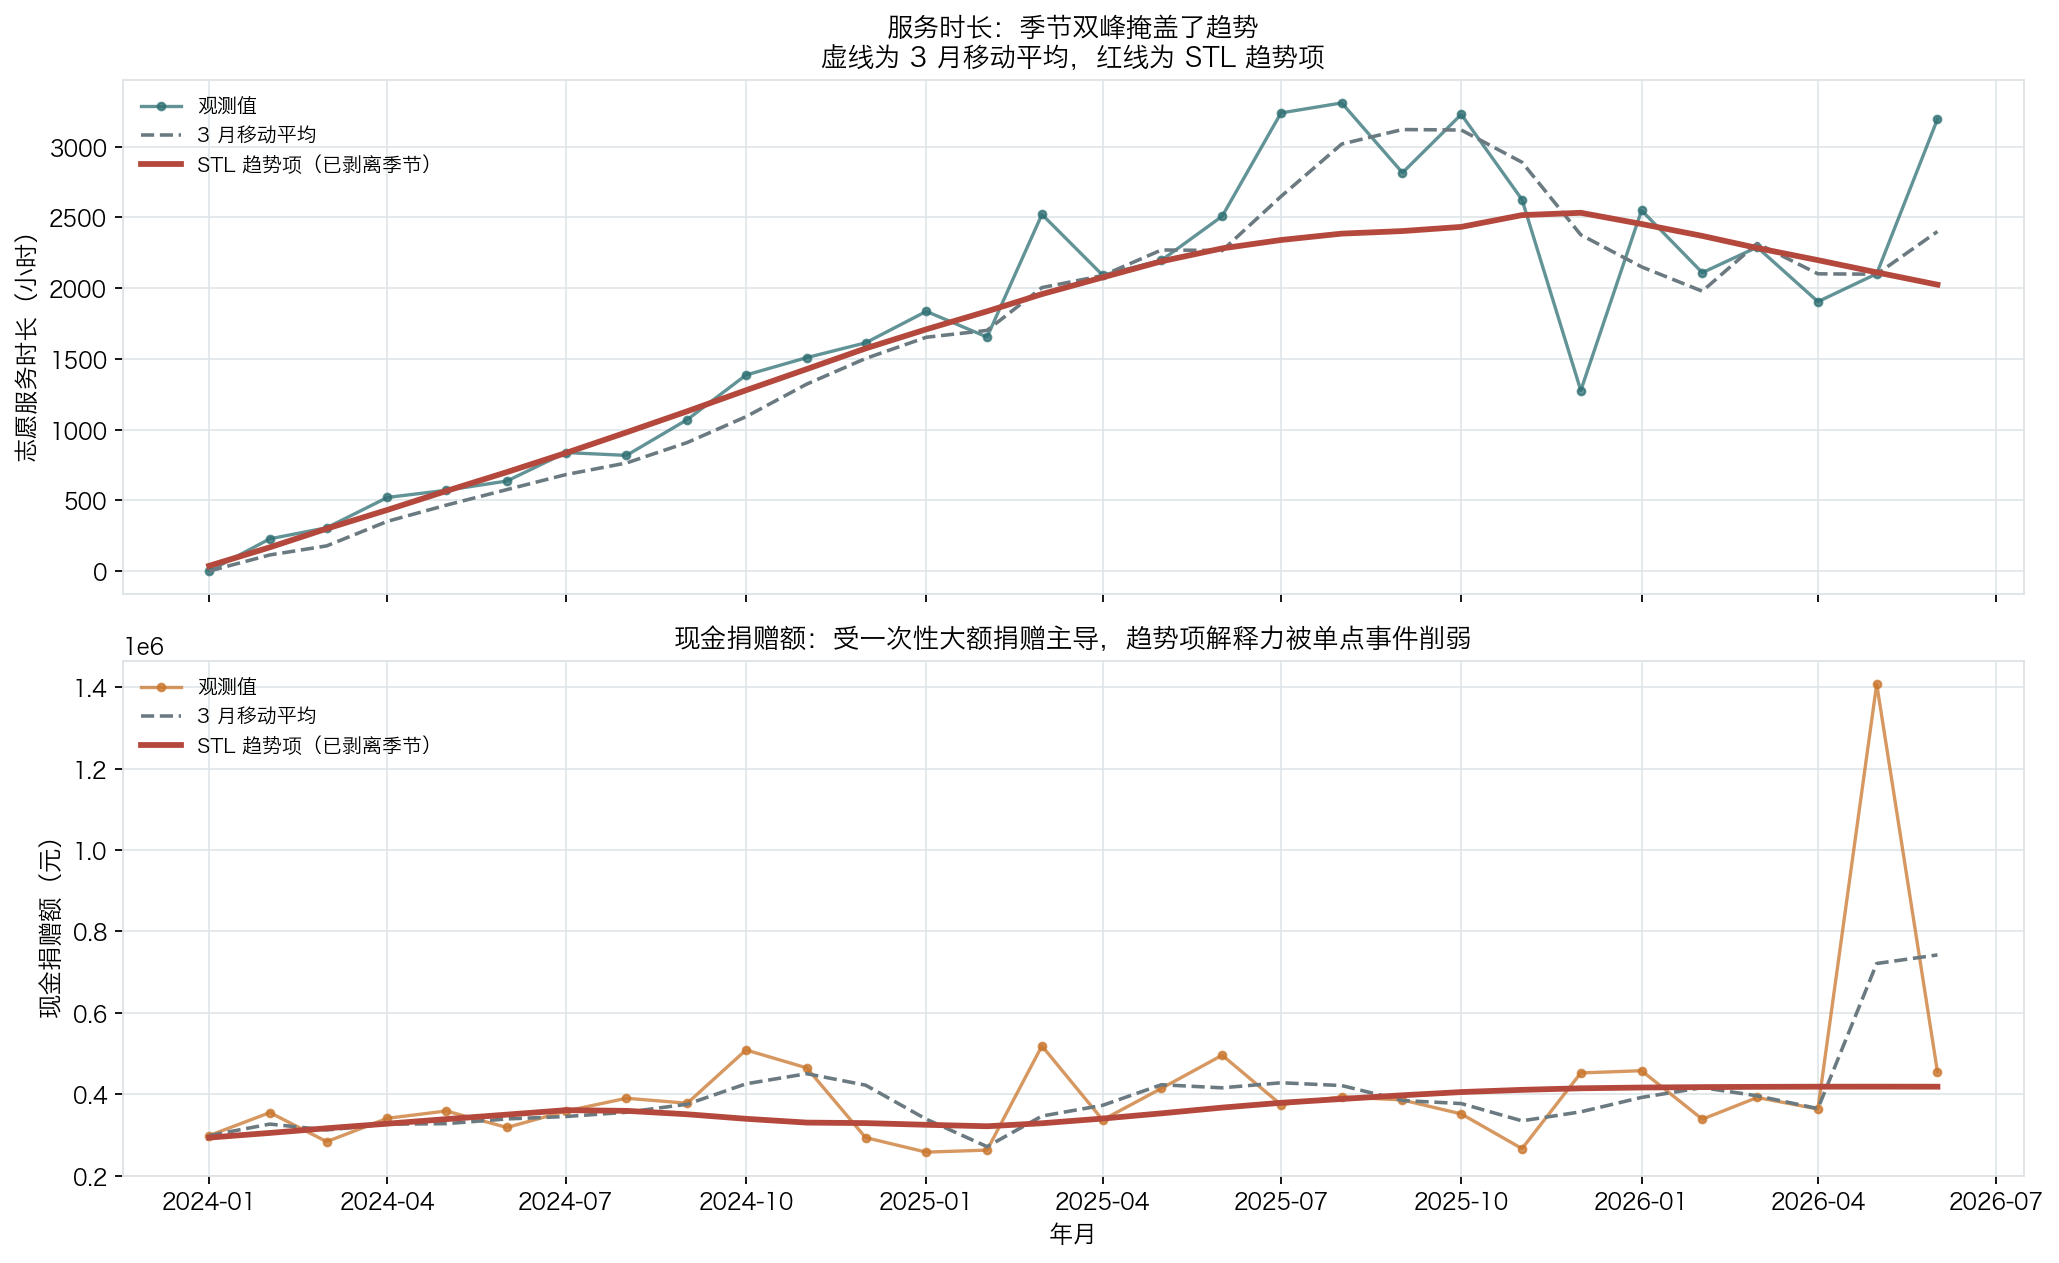

读法：观测值（点线）与趋势项（红线）的差距就是季节与残差；判断业务好坏要看红线方向，不要看单月观测值。
（本 notebook 自绘图表已保存：reports/figures/nb03_trend_overview.png）


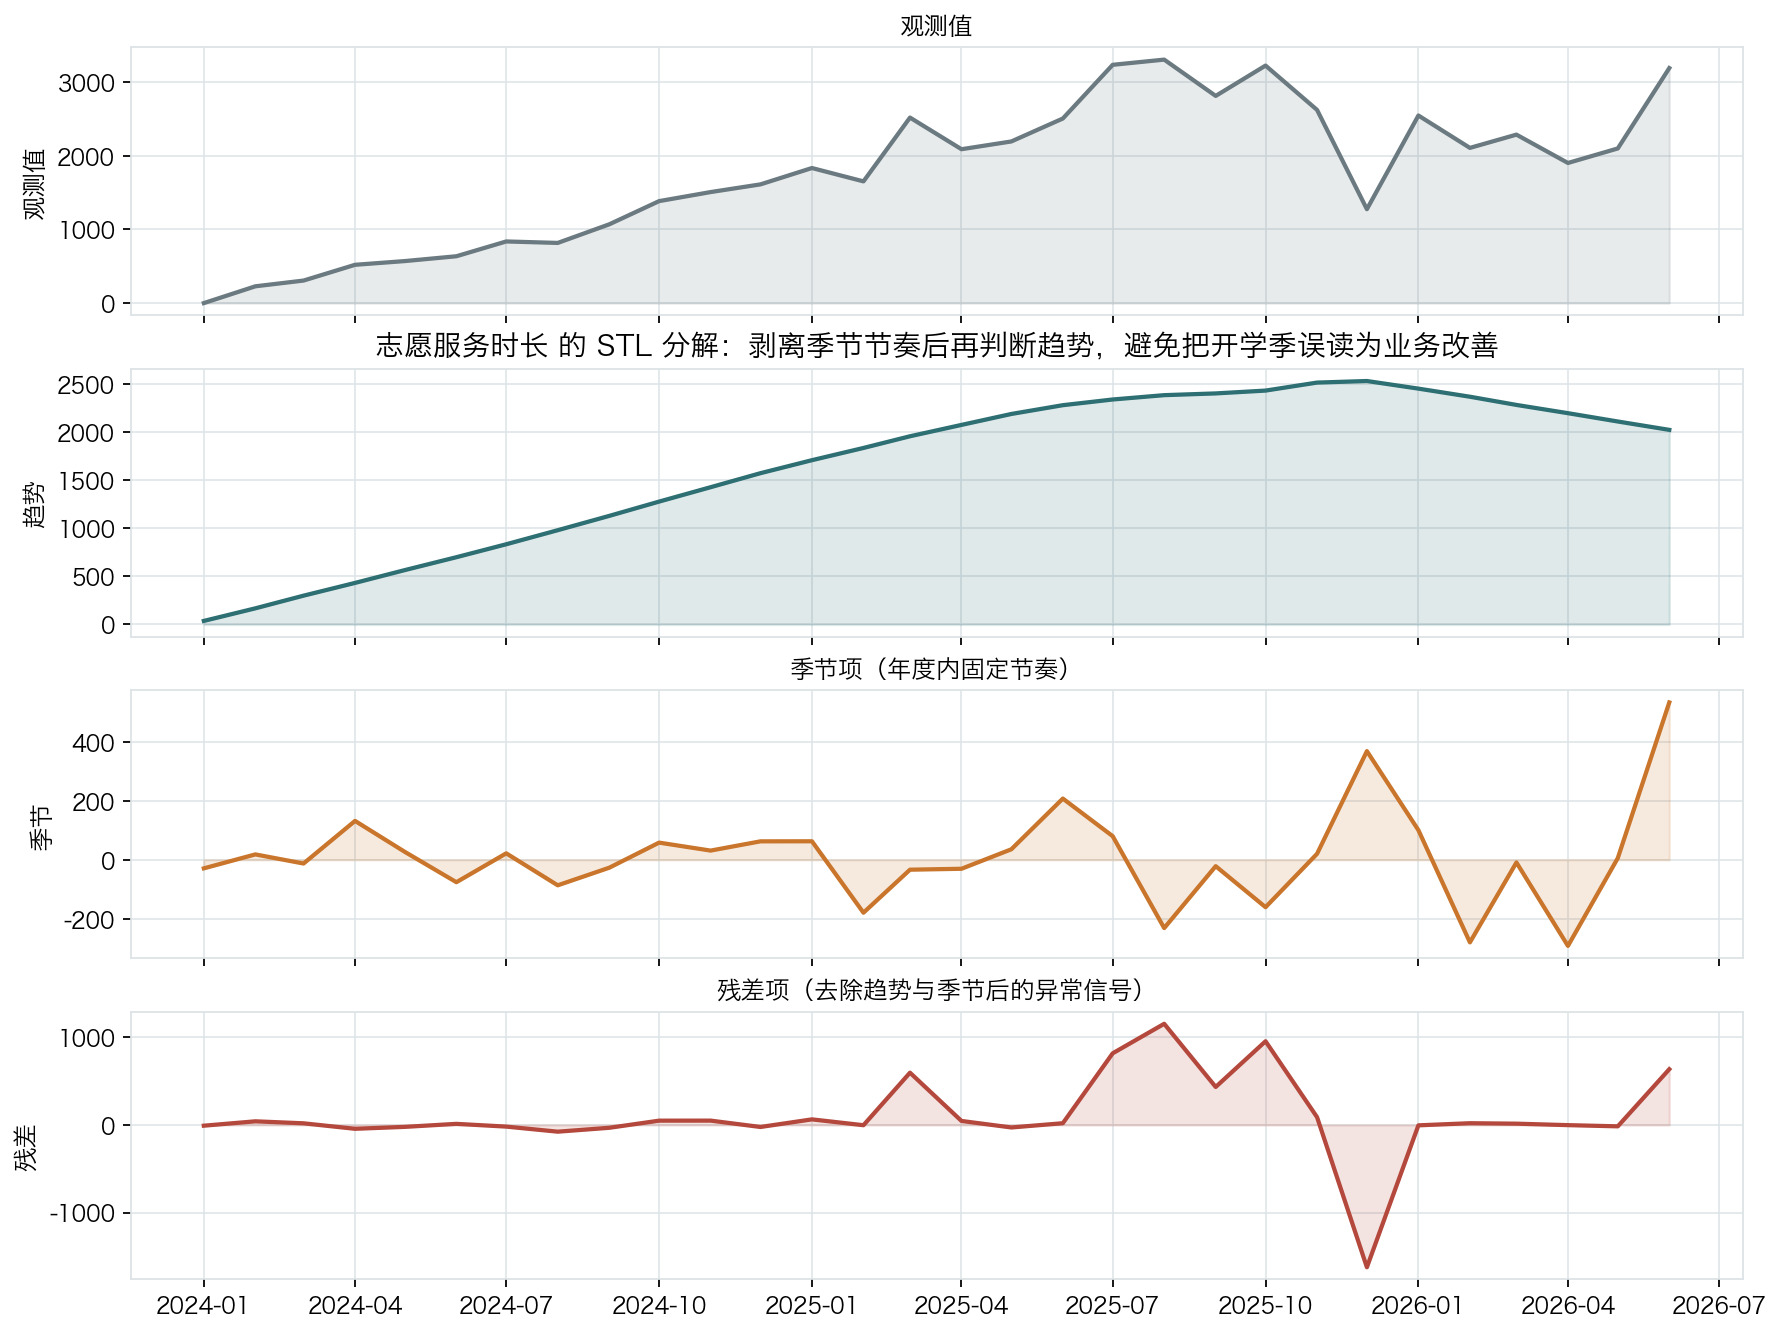

管道产出的 STL 四联图：观测值/趋势/季节/残差。残差项是异常检测的核心输入。
单笔最大捐赠出现在 2026-05，金额 850,000 元；剔除后该月捐赠额为 558,192 元，差异 60.4%


,含大额捐赠,剔除单笔最大捐赠,差异占比
年月,,,
2026-05,1408192.01,558192.01,0.6
2025-03,518681.50,518681.50,0.0
2024-10,508712.51,508712.51,0.0
2025-06,495750.87,495750.87,0.0
2024-11,464567.50,464567.50,0.0


In [2]:
display(tsummary)

service_key = "志愿服务时长"
donation_key = "现金捐赠额"

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, key, color, unit in zip(
    axes, [service_key, donation_key],
    [cfg.color("primary"), cfg.color("secondary")],
    ["小时", "元"],
):
    df = trends[key]
    idx = pd.to_datetime(df.index + "-01")
    ax.plot(idx, df["观测值"], "-o", ms=3.4, lw=1.5, color=color, alpha=0.75, label="观测值")
    ax.plot(idx, df["3月移动平均"], lw=1.6, ls="--", color=cfg.color("neutral"), label="3 月移动平均")
    if "趋势" in df.columns:
        ax.plot(idx, df["趋势"], lw=2.6, color=cfg.color("danger"), label="STL 趋势项（已剥离季节）")
    ax.set_ylabel(f"{key}（{unit}）")
    ax.legend(loc="upper left", fontsize=9)
axes[0].set_title("服务时长：季节双峰掩盖了趋势\n虚线为 3 月移动平均，红线为 STL 趋势项", fontsize=12)
axes[1].set_title("现金捐赠额：受一次性大额捐赠主导，趋势项解释力被单点事件削弱", fontsize=12)
axes[1].set_xlabel("年月")
fig.tight_layout()
show(fig, "nb03_trend_overview",
     "读法：观测值（点线）与趋势项（红线）的差距就是季节与残差；"
     "判断业务好坏要看红线方向，不要看单月观测值。")

pipeline_figure("03_stl_decomposition.png",
                "管道产出的 STL 四联图：观测值/趋势/季节/残差。残差项是异常检测的核心输入。")

# 剔除一次性大额捐赠后的可比口径（口径变更必须显式说明，否则会误读为"收入下滑"）
don = star["fact_donation"].copy()
don["年月"] = pd.to_datetime(don["date_key"].astype(str), format="%Y%m%d", errors="coerce").dt.strftime("%Y-%m")
monthly_don = don.groupby("年月")["amount_cny"].sum()
top_gift_month = monthly_don.idxmax()
top_gift_sum = float(don.loc[don["年月"] == top_gift_month, "amount_cny"].max())
monthly_ex = don.loc[don["amount_cny"] < top_gift_sum].groupby("年月")["amount_cny"].sum()
compare = pd.DataFrame({"含大额捐赠": monthly_don, "剔除单笔最大捐赠": monthly_ex}).fillna(0.0)
compare["差异占比"] = ((compare["含大额捐赠"] - compare["剔除单笔最大捐赠"]) / compare["含大额捐赠"]).round(4)
print(f"单笔最大捐赠出现在 {top_gift_month}，金额 {top_gift_sum:,.0f} 元；"
      f"剔除后该月捐赠额为 {compare.loc[top_gift_month, '剔除单笔最大捐赠']:,.0f} 元，"
      f"差异 {compare.loc[top_gift_month, '差异占比']:.1%}")
display(compare.loc[monthly_don.nlargest(5).index].round(2))

**怎么读趋势**：

- **服务时长的趋势项与观测值明显不同步**。观测值在盛夏与深秋冲高、在冬季塌陷，而趋势项更平缓——如果只看观测值，
  会把"每年都有的季节高峰"误读为新项目的成效。**这是公益项目汇报中最常见的统计误用**。
- **现金捐赠额的趋势项被单点事件主导**。一笔大额定向捐赠就能让整个季度的曲线抬升，
  它当然要计入收入，但在做"可持续筹资能力"判断时必须使用**剔除该笔后的可比口径**（上面代码已给出）。
  对捐赠人披露、对理事会汇报，两个口径都要给，并明确标注差异。
- **趋势项方向要结合两个指标一起看**：如果服务时长趋势向上而捐赠额趋势（可比口径）持平，
  说明组织在用志愿人力替代资金投入——这可持续性有限，因为志愿者时间也有上限。

> 汇报建议：对外材料里每个趋势结论都应标注"是否已剥离季节"与"是否包含一次性大额捐赠"。
> 两句口径注释能避免大量误读。

## 2. 季节节奏：排班与预算的时间表

公益服务受气候、学期、农时与外出务工潮影响，季节性是**可预测**的。
把月度均值换算成"相对强度指数"（1.0 = 全年月均），就能把季节节奏变成排班表与预算节奏的输入。

,month_num,月均,标准差,年数,相对强度指数,月度名称
0,10,2306.365000,1302.304486,2,1.281,10月
1,6,2112.604444,1323.434665,3,1.174,6月
2,11,2066.725000,789.463508,2,1.148,11月
3,8,2062.881667,1761.117792,2,1.146,8月
4,7,2037.603333,1697.065703,2,1.132,7月
5,9,1942.648333,1233.719842,2,1.079,9月
6,3,1705.235556,1217.135360,3,0.947,3月
7,5,1622.775556,912.114762,3,0.902,5月
8,4,1505.021111,857.808564,3,0.836,4月
9,1,1461.361111,1314.910511,3,0.812,1月


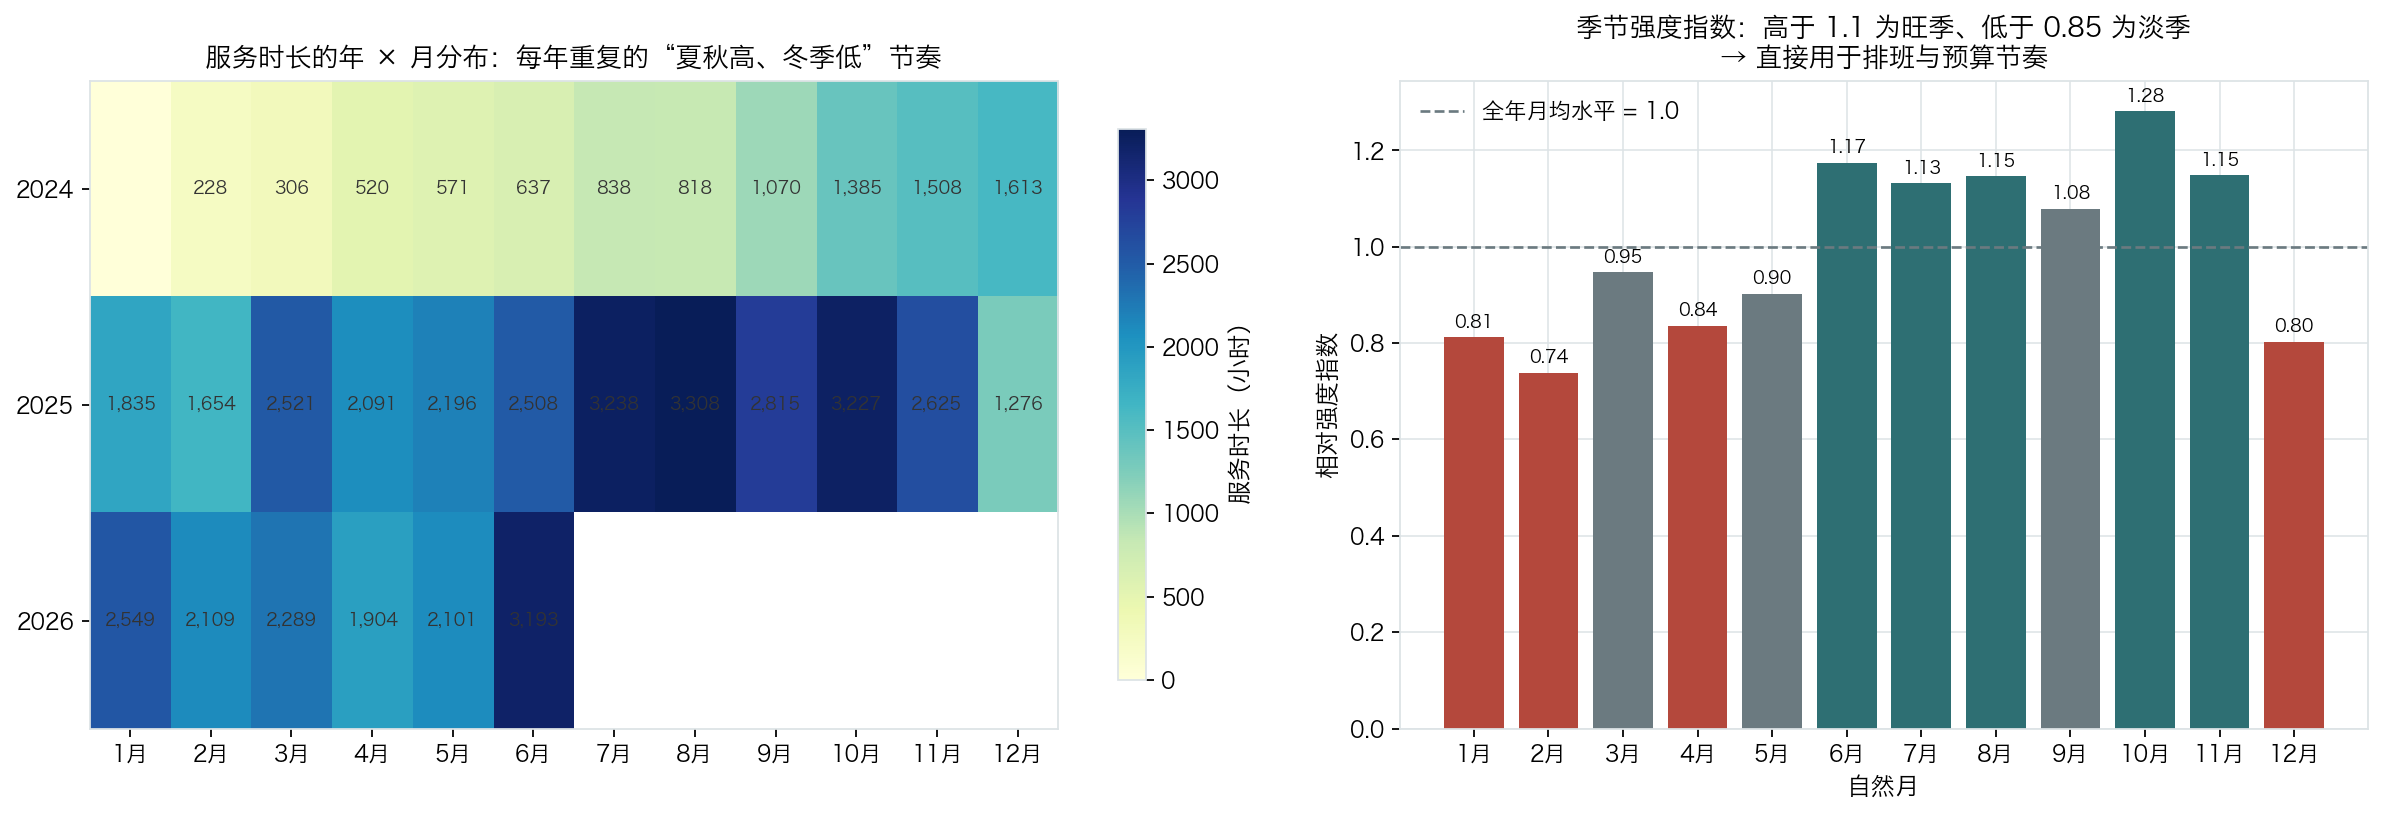

最强月份是 10月（指数 1.28），最弱是 2月（指数 0.74），季节性极差 1.7 倍。
（本 notebook 自绘图表已保存：reports/figures/nb03_seasonality.png）


In [3]:
season = monthly_seasonality(panel, metric="service_hours")
display(season)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
panel_s = panel.copy()
panel_s["年"] = pd.to_datetime(panel_s["month_dt"]).dt.year.astype(str)
panel_s["月"] = pd.to_datetime(panel_s["month_dt"]).dt.month
pivot = panel_s.pivot_table(index="年", columns="月", values="service_hours", aggfunc="sum").reindex(
    columns=range(1, 13), fill_value=0.0)
im = ax.imshow(pivot.to_numpy(), aspect="auto", cmap="YlGnBu")
ax.set_xticks(range(12), [f"{m}月" for m in range(1, 13)])
ax.set_yticks(range(len(pivot)), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.iloc[i, j]
        if v > 0:
            ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=8,
                    color="white" if v > pivot.to_numpy().max() * 0.6 else "#333333")
ax.set_title("服务时长的年 × 月分布：每年重复的“夏秋高、冬季低”节奏", fontsize=12)
ax.grid(False)
fig.colorbar(im, ax=ax, label="服务时长（小时）", shrink=0.85)

ax = axes[1]
s = season.sort_values("month_num")
colors = [cfg.color("danger") if v < 0.85 else (cfg.color("primary") if v > 1.1 else cfg.color("neutral"))
          for v in s["相对强度指数"]]
ax.bar(s["月度名称"], s["相对强度指数"], color=colors)
ax.axhline(1.0, color=cfg.color("neutral"), ls="--", lw=1.2, label="全年月均水平 = 1.0")
for i, v in enumerate(s["相对强度指数"]):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=8)
ax.set_ylabel("相对强度指数")
ax.set_xlabel("自然月")
ax.set_title("季节强度指数：高于 1.1 为旺季、低于 0.85 为淡季\n→ 直接用于排班与预算节奏", fontsize=12)
ax.legend()
fig.tight_layout()
show(fig, "nb03_seasonality",
     f"最强月份是 {s.loc[s['相对强度指数'].idxmax(), '月度名称']}"
     f"（指数 {s['相对强度指数'].max():.2f}），最弱是 {s.loc[s['相对强度指数'].idxmin(), '月度名称']}"
     f"（指数 {s['相对强度指数'].min():.2f}），季节性极差 {s['相对强度指数'].max() / s['相对强度指数'].min():.1f} 倍。")

**把季节性变成管理动作**：

- **旺季前移准备**：旺季的服务量是淡季的数倍，志愿者排班、物资采购、交通协调都要提前一个月启动，
  否则会出现"旺季来了、人还没到位"，直接体现为满意度下滑。
- **淡季不是"没事做"**：淡季应当安排培训、档案整理、需求摸排与筹资拜访——把人力从服务交付转向能力建设与资源拓展。
  这正好对应下一节要讲的"冬季活跃度骤降"异常：它是真实季节性，但也是可以主动管理的窗口期。
- **预算节奏要匹配季节**：如果预算按月度平均下拨，旺季会资金紧张、淡季大量结余，年底出现"突击花钱"，
  这也是项目执行率异常（跨期入账）的制度性成因。

> 建议做法：把"相对强度指数"写进年度预算编制模板，按指数分配月度额度，而不是平均 12 等分。

## 3. 异常检测：多方法投票，而不是单方法拍脑袋

单一方法都有系统性缺陷：3σ 假设近似正态（本数据的金额强右偏，会漏报或误报）、
IQR 只看箱线规则、孤立森林对参数敏感。项目采用**投票制**：多种方法各自判定，
至少两种方法同时命中才标记为高置信异常，显著降低假阳性。

检测方法列：['zscore', 'modified_zscore', 'iqr', 'trend_resid', 'stl_resid', 'iforest']
参与投票的检测方法共 6 种；检出整体层面异常点 4 个（配置要求至少 2 种方法一致）


,年月,指标,观测值,投票数,偏离中位数,方向,判定方法
0,2025-12,志愿服务时长,1.275997e+03,2,-0.317485,偏低,STL 残差+孤立森林
1,2025-12,活跃志愿者数,2.630000e+02,3,-0.157051,偏低,去趋势 Z 分数+STL 残差+孤立森林
2,2026-03,预算执行率,7.922124e-01,5,-0.145967,偏低,3σ 准则+稳健 Z 分数(MAD)+Tukey 箱线+去趋势 Z 分数+孤立森林
3,2026-05,现金捐赠额,1.408192e+06,6,2.817723,偏高,3σ 准则+稳健 Z 分数(MAD)+Tukey 箱线+去趋势 Z 分数+STL 残差+孤立森林


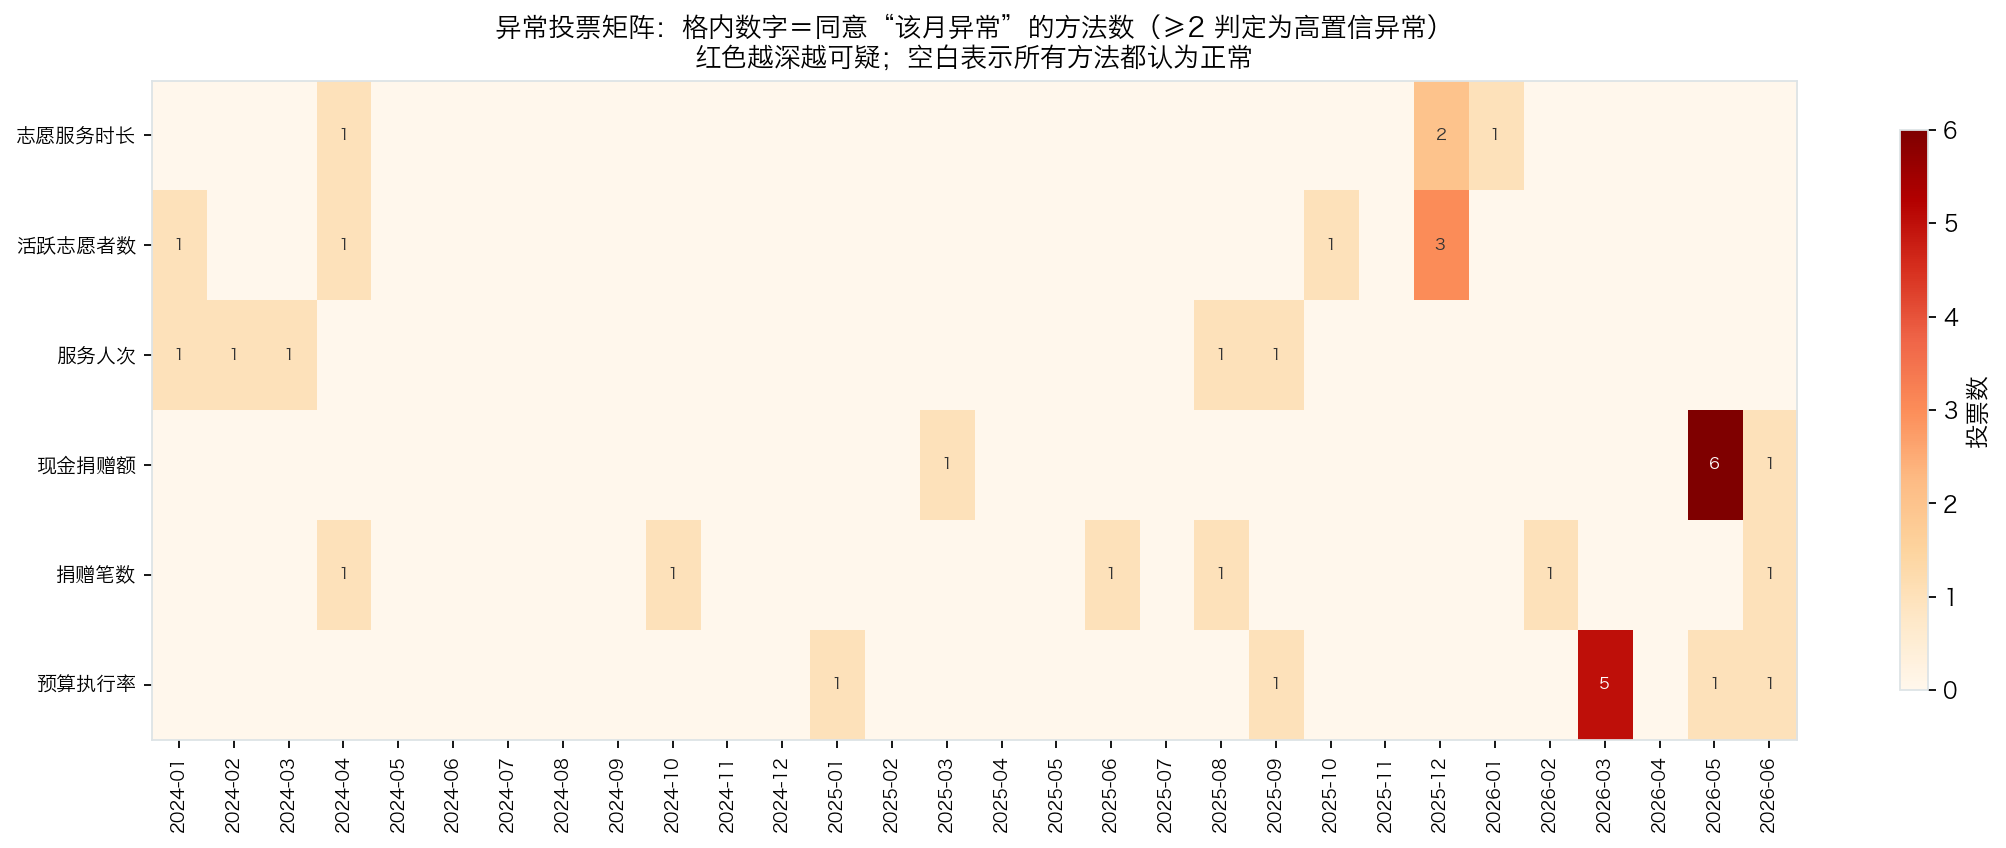

注意：捐赠相关指标的高分月集中在一次性大额捐赠发生的月份（业务事件），而预算执行率的异常月通常伴随跨期入账（口径问题）——性质不同，处置方式也必须不同。
（本 notebook 自绘图表已保存：reports/figures/nb03_vote_matrix.png）


In [4]:
ANOM_METRICS = {
    "志愿服务时长": "service_hours",
    "活跃志愿者数": "active_volunteers",
    "服务人次": "service_visits",
    "现金捐赠额": "donation_amount",
    "捐赠笔数": "donation_count",
    "预算执行率": "execution_rate",
}
vote_matrix = {}
detail = {}
for label, col in ANOM_METRICS.items():
    if col not in panel.columns:
        continue
    series = panel.set_index("year_month")[col].astype(float)
    res = detect_anomalies(series, cfg, label=label)
    detail[label] = res
    vote_matrix[label] = res.set_index("期间")["投票数"]
votes = pd.DataFrame(vote_matrix).T.fillna(0).astype(int)

monthly_anom = detect_monthly_anomalies(cfg, panel)
# 方法列 = 检测结果中除元数据以外的列，动态识别，避免写死方法名（方法集会随配置变化）
META_COLS = {"期间", "指标", "投票数", "是否异常", "判定方法", "观测值", "稳健Z分数", "偏离中位数", "方向"}
method_cols = [c for c in detail[list(detail)[0]].columns if c not in META_COLS]
n_methods = len(method_cols)
print(f"检测方法列：{method_cols}")
print(f"参与投票的检测方法共 {n_methods} 种；检出整体层面异常点 {len(monthly_anom)} 个"
      f"（配置要求至少 {int(cfg.analysis['anomaly']['consensus_min_votes'])} 种方法一致）")
display(monthly_anom[["年月", "指标", "观测值", "投票数", "偏离中位数", "方向", "判定方法"]])

fig, ax = plt.subplots(figsize=(14, 5.4))
im = ax.imshow(votes.to_numpy(), aspect="auto", cmap="OrRd", vmin=0,
               vmax=max(1, votes.to_numpy().max()))
ax.set_xticks(range(votes.shape[1]), votes.columns, rotation=90, fontsize=8)
ax.set_yticks(range(votes.shape[0]), votes.index, fontsize=9)
threshold = int(cfg.analysis["anomaly"]["consensus_min_votes"])
for i in range(votes.shape[0]):
    for j in range(votes.shape[1]):
        v = votes.iloc[i, j]
        if v:
            ax.text(j, i, str(v), ha="center", va="center", fontsize=7.5,
                    color="white" if v >= votes.to_numpy().max() * 0.7 else "#333333",
                    fontweight="bold" if v >= threshold else "normal")
ax.set_title(f"异常投票矩阵：格内数字＝同意“该月异常”的方法数（≥{threshold} 判定为高置信异常）\n"
             "红色越深越可疑；空白表示所有方法都认为正常", fontsize=12)
ax.grid(False)
fig.colorbar(im, ax=ax, label="投票数", shrink=0.85)
fig.tight_layout()
show(fig, "nb03_vote_matrix",
     "注意：捐赠相关指标的高分月集中在一次性大额捐赠发生的月份（业务事件），"
     "而预算执行率的异常月通常伴随跨期入账（口径问题）——性质不同，处置方式也必须不同。")

**投票矩阵怎么读**：

- **颜色深 = 多个方法同时认为异常**。这类点置信度最高，应优先排查。投票数恰好等于阈值（2 票）的点属于"边界异常"，
  需要人工看一眼——它们往往处于分布边缘，是噪声还是真信号取决于业务背景。
- **指标之间的异常月份高度重叠**（例如服务时长与活跃志愿者数同时在某月偏低），说明这不是单指标噪声，
  而是同一件业务事件的多个侧面——这是重要的交叉验证信号。
- **捐赠类指标的异常需要单独对待**：金额强右偏时，任何基于方差的方法都会被大额捐赠拉爆。
  这里的高投票数反映的是"极值确实存在"，而不是"数据有问题"。

> 操作建议：把票数 ≥ 阈值且**同时出现在两个以上指标**的月份列为"必须复盘月"，
> 其余边界点列入观察名单，避免排查工作量被噪声淹没。

## 4. 下钻与归因：是谁把整体拉偏了

总量异常只是警报，不是结论。必须回答三件事：**哪个县、哪类项目、是业务还是数据问题**。
项目的 `attribute_anomaly` 会把当期与历史月均做维度分解，给出每个维度成员的偏离贡献；
贡献占比最高的那个单元就是"主责单元"。

In [5]:
county_anom = detect_county_month_anomalies(cfg, star)
print(f"县 × 月下钻检出 {len(county_anom)} 个局部异常点（这些点在整体层面可能完全看不出来）")
display(county_anom if len(county_anom) else pd.DataFrame({"提示": ["无"]}))

# 从检出的异常中挑出投票数最高的捐赠异常与时长异常做归因
def _pick(metric_name: str):
    sub = monthly_anom[monthly_anom["指标"] == metric_name]
    if len(sub):
        row = sub.sort_values("投票数", ascending=False).iloc[0]
        return str(row["年月"]), str(metric_name)
    return None, None

targets = [_pick("现金捐赠额"), _pick("志愿服务时长")]
targets = [t for t in targets if t[0]]

attributions = {}
for period, metric in targets:
    info = attribute_anomaly(cfg, star, period, metric)
    attributions[(period, metric)] = info
    print("=" * 74)
    print(f"归因：{info['年月']} / {info['指标']}")
    for k in ["当期值", "历史中位月", "偏离量", "偏离幅度", "主责县域", "主责县域偏离贡献占比",
              "主责项目类别", "当期修正率", "历史修正率中位数", "初步成因判断"]:
        print(f"  {k:>14}：{info[k]}")
    breakdown = info["维度分解"]
    for dim, name in [("county", "县域"), ("category", "项目类别")]:
        frame = breakdown[dim].head(5).copy()
        frame["偏离占比"] = (frame["偏离占比"] * 100).round(2).astype(str) + "%"
        print(f"  ── {name}维分解 ──")
        display(frame.round(2))

# SQL 独立复核：县域月度偏离度与预算执行异常项目
sql04 = run_sql_file(cfg, "04_analysis_queries.sql")
errors = [(lab, df) for lab, df in sql04 if "error" in df.columns]
print(f"04_analysis_queries.sql 执行 {len(sql04)} 条查询，失败 {len(errors)} 条")


def fetch04(key: str):
    for label, frame in sql04:
        if key in label:
            return label, frame
    raise KeyError(key)


for key in ["县域月度服务时长的偏离度", "月度预算执行率异常项目"]:
    label, frame = fetch04(key)
    print(f"\n【{label}】")
    display(frame.head(8))

县 × 月下钻检出 3 个局部异常点（这些点在整体层面可能完全看不出来）


,县,年月,观测值,偏离中位数,方向,投票数,判定方法
0,香格里拉市,2025-12,562.6,-0.362,偏低,2,STL 残差+孤立森林
1,维西傈僳族自治县,2026-05,1073.1,1.405,偏高,2,Tukey 箱线+孤立森林
2,维西傈僳族自治县,2026-06,1400.9,2.140,偏高,5,3σ 准则+稳健 Z 分数(MAD)+Tukey 箱线+去趋势 Z 分数+孤立森林


归因：2026-05 / 现金捐赠额
             当期值：1408192.01
           历史中位月：368856.53
             偏离量：1039335.48
            偏离幅度：2.8177
            主责县域：香格里拉市
      主责县域偏离贡献占比：0.7546
          主责项目类别：乡村振兴
           当期修正率：0.0128
        历史修正率中位数：0.0117
          初步成因判断：业务事件或真实波动（记录质量平稳）
  ── 县域维分解 ──


,当期,历史月均,偏离,偏离占比
county,,,,
香格里拉市,1063543.18,559.17,1062984.01,75.46%
维西傈僳族自治县,213119.50,500.68,212618.82,15.09%
UNKNOWN,97728.06,649.40,97078.66,6.89%
德钦县,33801.27,498.81,33302.46,2.36%
州外,0.00,2749.54,-2749.54,-0.2%


  ── 项目类别维分解 ──


...

,当期,历史月均,偏离,偏离占比
category,,,,
助老敬老,502.67,3.58,499.09,40.17%
助学支教,264.28,4.62,259.66,20.9%
生态环保,118.27,4.20,114.07,9.18%
乡村振兴,115.53,4.14,111.39,8.97%
助残扶弱,91.52,3.76,87.76,7.06%


04_analysis_queries.sql 执行 20 条查询，失败 0 条

【分析：县域月度服务时长的偏离度】


,年月,县,服务时长,县历史均值,Z分数,判定
0,2026-06,维西傈僳族自治县,1389.0,496.0,3.099,异常
1,2025-07,香格里拉市,1861.7,882.9,2.159,异常
2,2025-08,德钦县,1101.9,471.8,2.126,异常
3,2026-05,维西傈僳族自治县,1073.1,496.0,2.002,异常
4,2025-10,德钦县,1019.7,471.8,1.849,关注
5,2025-08,香格里拉市,1702.0,882.9,1.807,关注
6,2024-02,香格里拉市,86.3,882.9,-1.757,关注
7,2025-10,香格里拉市,1650.6,882.9,1.693,关注



【分析：月度预算执行率异常项目（跨期入账 / 执行滞后排查）】


,年月,项目名称,县,计划支出,实际支出,当月执行率,项目平均执行率,偏离度
0,2024-08,UNKNOWN,UNKNOWN,5604.0,8986.0,1.6034,0.9500,0.6534
1,2026-03,维西-高原雏鹰课堂(1期),维西傈僳族自治县,48839.0,25919.0,0.5307,1.0127,-0.4820
2,2026-05,德钦县-松茸采摘技能培训,德钦县,60200.0,81146.0,1.3479,0.9455,0.4024
3,2025-10,维西-高原雏鹰课堂(1期),维西傈僳族自治县,27119.0,38108.0,1.4052,1.0127,0.3925
4,2025-09,香格里拉 乡村电商人才培育,香格里拉市,7741.0,4252.0,0.5493,0.9097,-0.3604
5,2025-11,维西-高原雏鹰课堂(1期),维西傈僳族自治县,36747.0,50009.0,1.3609,1.0127,0.3482
6,2025-02,德钦县-一帮一助学行动,德钦县,15865.0,11176.0,0.7045,1.0461,-0.3416
7,2025-09,德钦县-松茸采摘技能培训,德钦县,24117.0,14908.0,0.6182,0.9455,-0.3273


**归因结果的三层解读**：

1. **主责单元**：偏离贡献占比最高的县/项目类别就是"谁把整体拉偏了"。如果最大贡献占比并不高（例如只有三成），
   说明偏离是**多点共同作用**的结果，不存在单一责任单元——这种情况通常对应普遍性的季节或政策因素，而不是某个片区的事故。
2. **性质判断**：`当期修正率` 与 `历史修正率中位数` 的对比是区分"数据错误"与"业务事件"的关键。
   修正率异常抬升（例如翻倍以上）说明该月的记录被大量截断/置缺，是**录入事故**的强信号；
   修正率平稳则说明记录质量正常，偏离来自真实业务。
3. **分解表的读法**：`偏离 = 当期 − 历史月均`，`偏离占比` 用于比较各单元的贡献大小（有正有负，可相互抵消）。
   要注意 `UNKNOWN` 行——如果它的偏离贡献异常大，说明问题出在**归属关系缺失**（台账与财务没对上），
   而不是某个具体项目的业务变化。这本身就是一条数据治理结论。

> 处置对照表：
> - 判定为**数据错误** → 回到清洗层加规则/回到源头修表单，并在指标口径中剔除或校正该月；
> - 判定为**业务事件** → **不要改数据**，而是在报告中披露事件、做情景调整，并评估是否需要应急资源；
> - 判定为**口径问题**（跨期入账） → 修正财务口径或做期间归属调整，避免把会计问题误读成执行滞后。

## 5. 数据错误通道：把"录入事故"从业务波动里摘出来

判断"业务事件 vs 数据错误"不能靠感觉，要靠**记录质量指标**：签到修正率、服务记录剔除率、悬空外键率。
它们衡量的是"数据被修复的比例"，与业务量无关。这类指标突增的月份，几乎必然是录入或接入环节出了问题。

数据错误特征曲线覆盖 29 个月；检出数据质量异常点 5 个


,县,年月,指标,观测值,偏离中位数,方向,投票数,判定方法
0,全州,2024-02,服务记录剔除率,0.1000,1.208,偏高,3,稳健 Z 分数(MAD)+Tukey 箱线+孤立森林
1,香格里拉市,2024-02,服务记录剔除率,0.0968,1.256,偏高,6,3σ 准则+稳健 Z 分数(MAD)+Tukey 箱线+去趋势 Z 分数+STL 残差+孤立森林
2,全州,2026-04,签到修正率,0.0341,1.915,偏高,2,Tukey 箱线+孤立森林
3,全州,2026-06,服务记录剔除率,0.3994,7.817,偏高,6,3σ 准则+稳健 Z 分数(MAD)+Tukey 箱线+去趋势 Z 分数+STL 残差+孤立森林
4,维西傈僳族自治县,2026-06,服务记录剔除率,0.6459,11.931,偏高,6,3σ 准则+稳健 Z 分数(MAD)+Tukey 箱线+去趋势 Z 分数+STL 残差+孤立森林


,年月,签到记录数,签到修正数,服务记录数,服务记录悬空键数,签到修正率,服务悬空键率,原始服务记录数,服务记录剔除率,原始签到记录数,签到记录剔除率
21,2025-11,634.0,4.0,681,14,0.0063,0.0206,704,0.0327,661.0,0.0408
22,2025-12,327.0,3.0,655,15,0.0092,0.0229,679,0.0353,342.0,0.0439
23,2026-01,623.0,10.0,599,11,0.0161,0.0184,633,0.0537,653.0,0.0459
24,2026-02,542.0,8.0,358,11,0.0148,0.0307,375,0.0453,568.0,0.0458
25,2026-03,541.0,5.0,328,5,0.0092,0.0152,346,0.0520,562.0,0.0374
26,2026-04,469.0,16.0,303,7,0.0341,0.0231,326,0.0706,489.0,0.0409
27,2026-05,545.0,7.0,380,11,0.0128,0.0289,393,0.0331,584.0,0.0668
28,2026-06,809.0,10.0,424,7,0.0124,0.0165,706,0.3994,843.0,0.0403


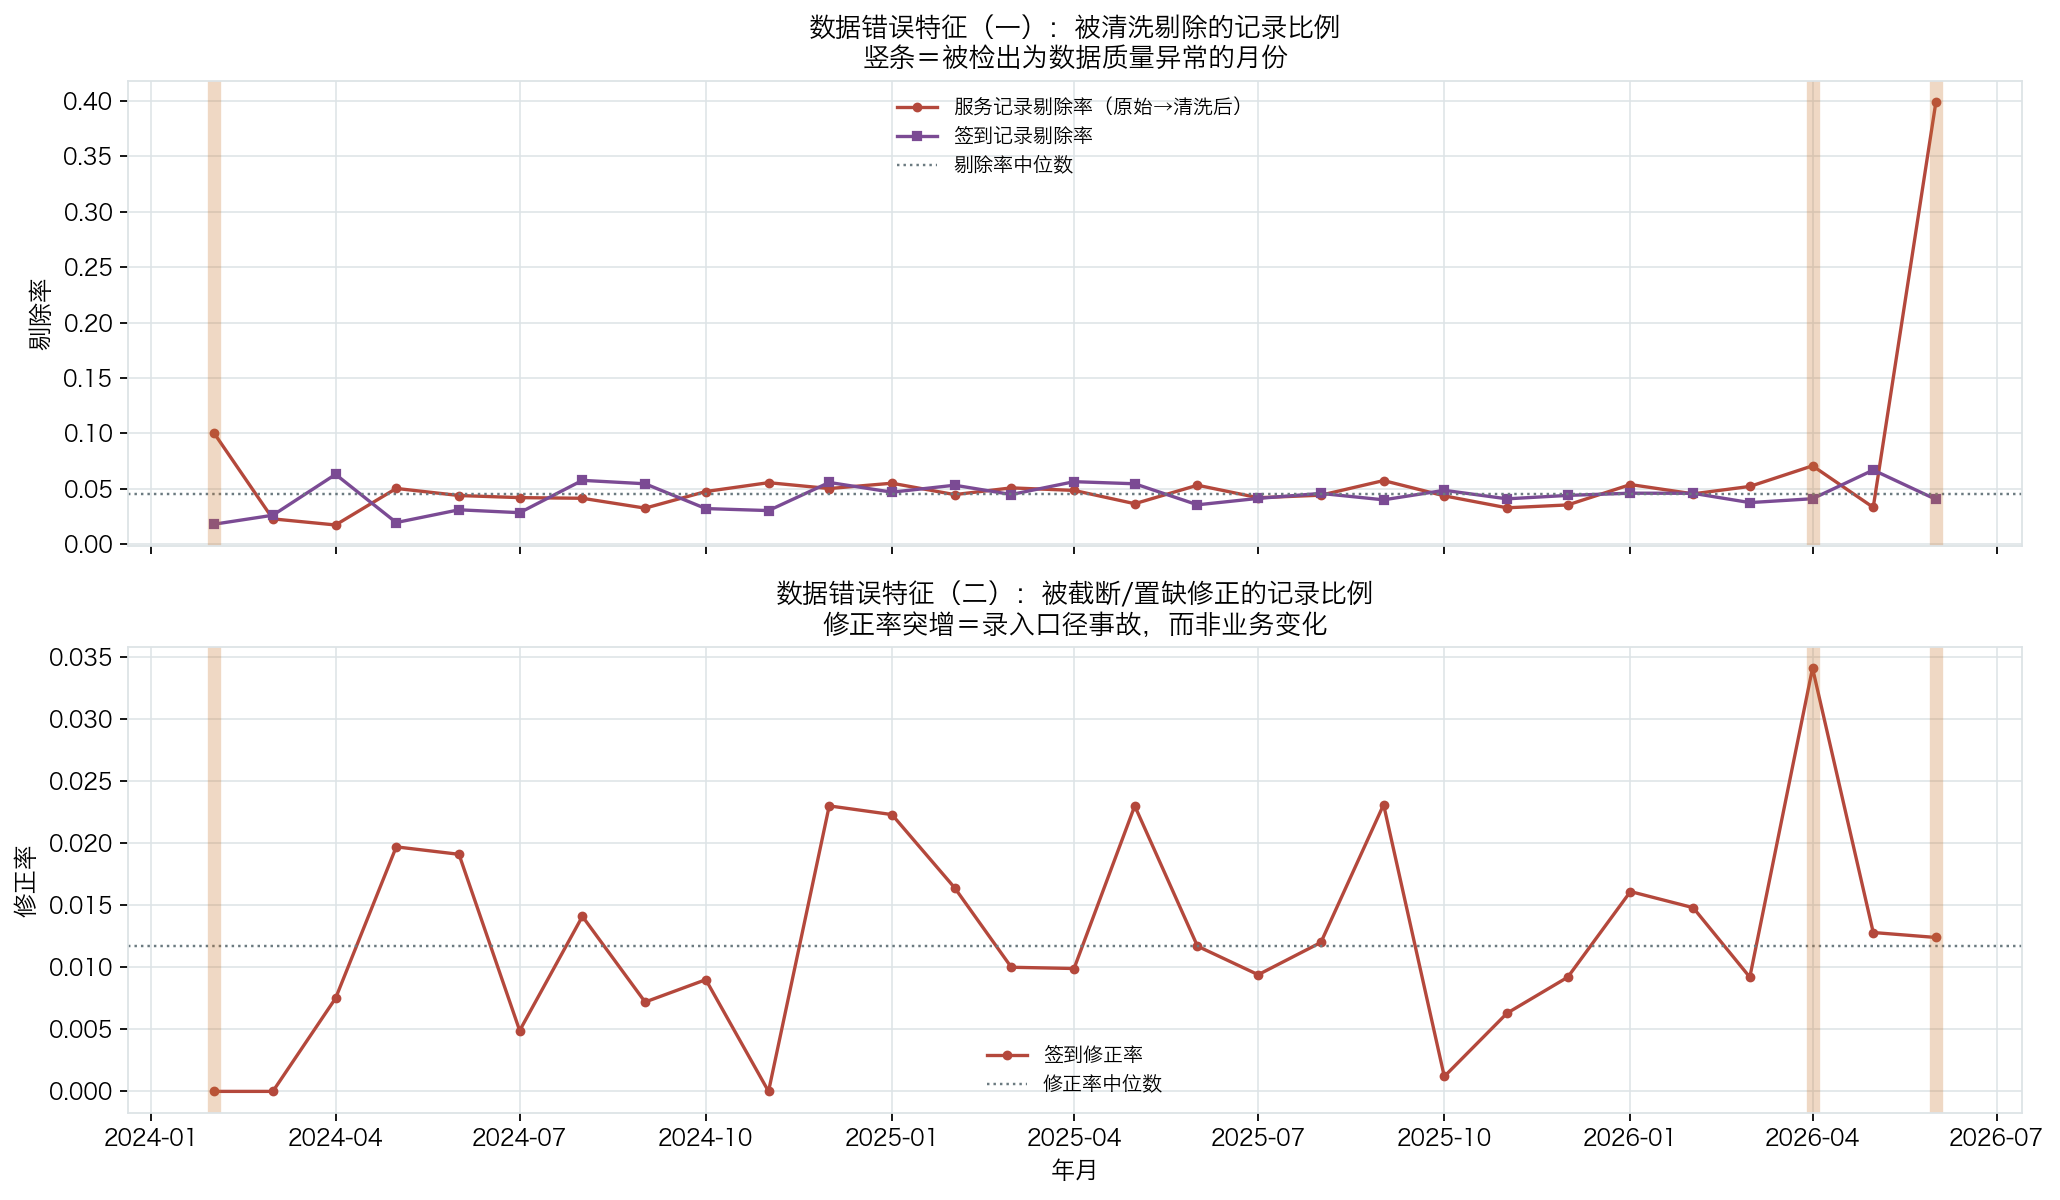

两图联动读：剔除率与修正率同时抬升的月份，是“数据错误”而非“业务变化”——这类月份的指标值必须校正后再用于考核。
（本 notebook 自绘图表已保存：reports/figures/nb03_quality_signature.png）


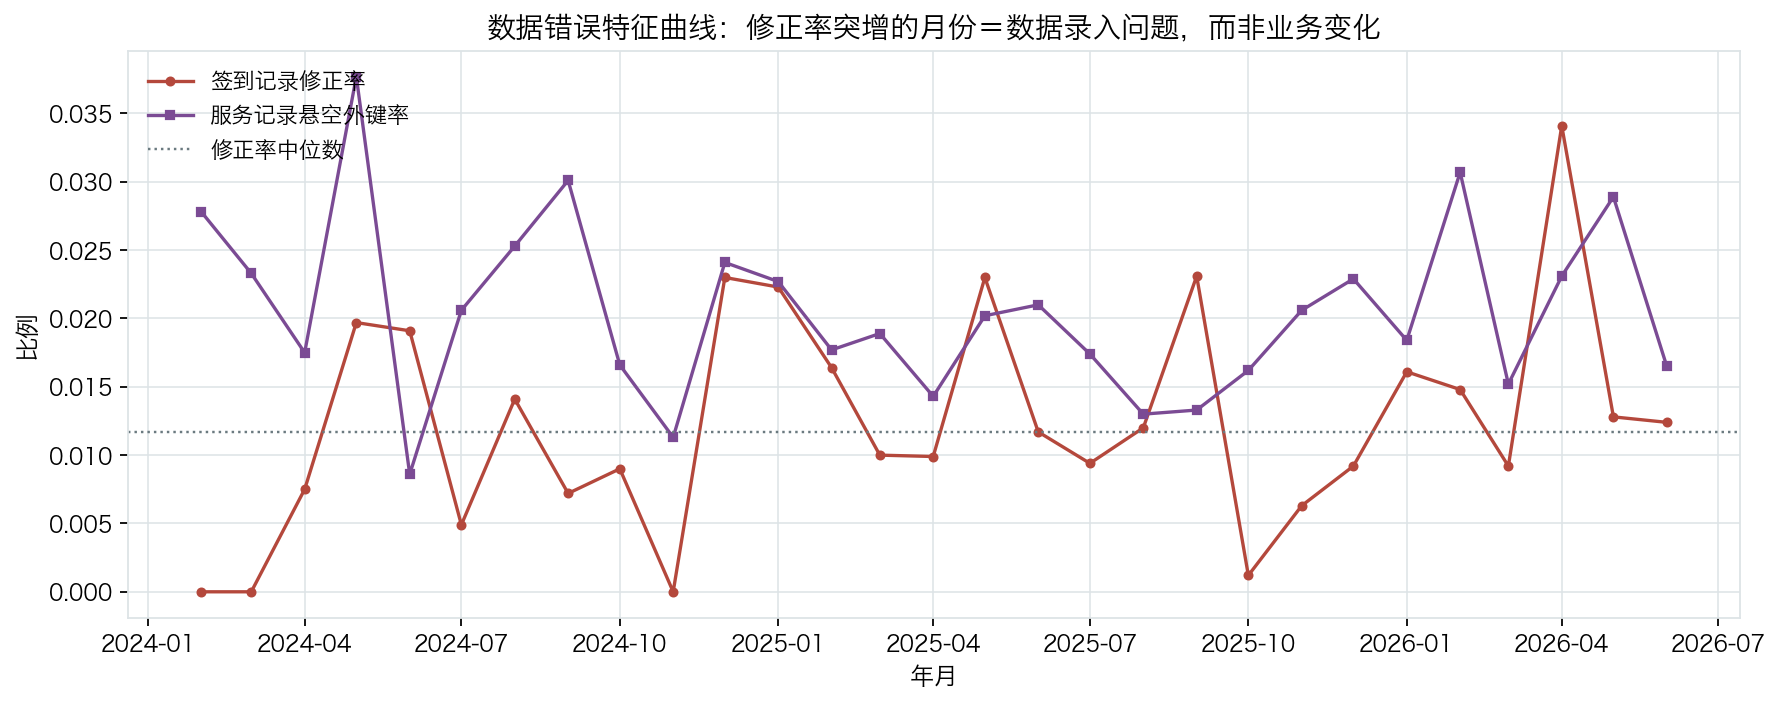

管道产出的同类图表，可与上图交叉比对。


In [6]:
qs = quality_signature(cfg, star)
data_errors = detect_data_error_anomalies(cfg, star)
print(f"数据错误特征曲线覆盖 {len(qs)} 个月；检出数据质量异常点 {len(data_errors)} 个")
display(data_errors if len(data_errors) else pd.DataFrame({"提示": ["未检出数据质量异常"]}))
display(qs.tail(8).round(4))

fig, axes = plt.subplots(2, 1, figsize=(13, 7.6), sharex=True)
x = pd.to_datetime(qs["年月"] + "-01")
flag_months = set(data_errors["年月"].astype(str)) if len(data_errors) else set()

ax = axes[0]
ax.plot(x, qs["服务记录剔除率"], "-o", ms=3.4, color=cfg.color("danger"), label="服务记录剔除率（原始→清洗后）")
ax.plot(x, qs["签到记录剔除率"], "-s", ms=3.4, color=cfg.color("accent"), label="签到记录剔除率")
ax.axhline(qs["服务记录剔除率"].median(), ls=":", color=cfg.color("neutral"), lw=1.1, label="剔除率中位数")
for m in flag_months:
    t = pd.Timestamp(m + "-01")
    if t in set(x):
        ax.axvline(t, color=cfg.color("secondary"), alpha=0.28, lw=6)
ax.set_ylabel("剔除率")
ax.set_title("数据错误特征（一）：被清洗剔除的记录比例\n竖条＝被检出为数据质量异常的月份", fontsize=12)
ax.legend(fontsize=9)

ax = axes[1]
ax.plot(x, qs["签到修正率"], "-o", ms=3.4, color=cfg.color("danger"), label="签到修正率")
ax.axhline(qs["签到修正率"].median(), ls=":", color=cfg.color("neutral"), lw=1.1, label="修正率中位数")
for m in flag_months:
    t = pd.Timestamp(m + "-01")
    if t in set(x):
        ax.axvline(t, color=cfg.color("secondary"), alpha=0.28, lw=6)
ax.set_ylabel("修正率")
ax.set_xlabel("年月")
ax.set_title("数据错误特征（二）：被截断/置缺修正的记录比例\n修正率突增＝录入口径事故，而非业务变化", fontsize=12)
ax.legend(fontsize=9)
fig.tight_layout()
show(fig, "nb03_quality_signature",
     "两图联动读：剔除率与修正率同时抬升的月份，是“数据错误”而非“业务变化”——"
     "这类月份的指标值必须校正后再用于考核。")

pipeline_figure("09_quality_signature.png", "管道产出的同类图表，可与上图交叉比对。")

**为什么这个通道不可省**：

- **业务事件不需要修数据，数据错误必须修数据**。若把维西某月的整表重复导入当成"服务量暴涨"写进年度总结，
  会直接抬高下一年度的目标基线；反之，若把德钦因暴雪封路导致的真实下滑当成"数据缺失"而剔除，
  就等于把不可抗力从账上抹掉，掩盖了应急资源的真实需求。
- **数据错误是可以被消除的，业务波动不能**。因此数据错误通道的运营价值更高：
  每一次检出都对应一个可以改进的表单、导入模板或对账流程。
- **剔除率与修正率的分母不同**：剔除率来自"原始记录数 vs 清洗后记录数"的对比（需要读原始数据），
  修正率来自清洗结果里的 `is_corrected` 标记。两者同时抬升时置信度最高。

> 运营建议：把"月度剔除率/修正率"纳入数据团队的服务水平指标（SLO），
> 例如"任何月份的剔除率不得超过中位数的 2 倍，否则触发录入流程复盘"。
> 这比事后在报告里解释异常要便宜得多。

## 6. 可验证性：用注入真值给检测打分

异常检测最容易陷入自说自话——"算法说这是异常，所以它是异常"。
本项目的数据在生成阶段就**故意植入了已知的异常**（含成因类型与偏离幅度），
因此可以用真值表给检测打分：哪些检出了、通过哪个通道检出的、哪些漏了、为什么漏。

,异常编号,植入月份,植入范围,植入指标,偏离方向,偏离幅度,真实成因类型,整体层面检出,县域下钻检出,数据错误通道检出,综合检出
0,ANOM-01,2026-04,香格里拉市,志愿服务时长,spike,+186%,数据错误,否,否,是,是
1,ANOM-02,2026-05,德钦县,志愿服务时长,drop,-63%,业务事件,否,否,否,否
2,ANOM-03,2026-05,全州,现金捐赠额,spike,+412%,业务事件,是,否,否,是
3,ANOM-04,2026-06,维西傈僳族自治县,服务人次,spike,+204%,数据错误,否,是,是,是
4,ANOM-05,2025-12,全州,活跃志愿者数,drop,-41%,业务事件,是,否,否,是
5,ANOM-06,2026-03,维西傈僳族自治县,预算执行率,drop,-34%,数据错误,是,否,否,是


,植入数,检出数,检出率
真实成因类型,,,
业务事件,3,2,0.667
数据错误,3,3,1.000


综合检出率：5/6 = 83.3%


,异常编号,植入月份,植入范围,植入指标,真实成因类型,实际偏离幅度,序列稳健变异系数,漏报原因,改进方向
0,ANOM-02,2026-05,德钦县,志愿服务时长,业务事件,-0.7192,0.3849,信噪比不足：相对局部趋势的实际偏离为 -72%，而该序列残差的稳健变异系数为 0.38，单点...,引入业务事件日历（天气/交通/节庆）作为外生变量，或改用 CUSUM 等变点检测识别缓变累积偏移


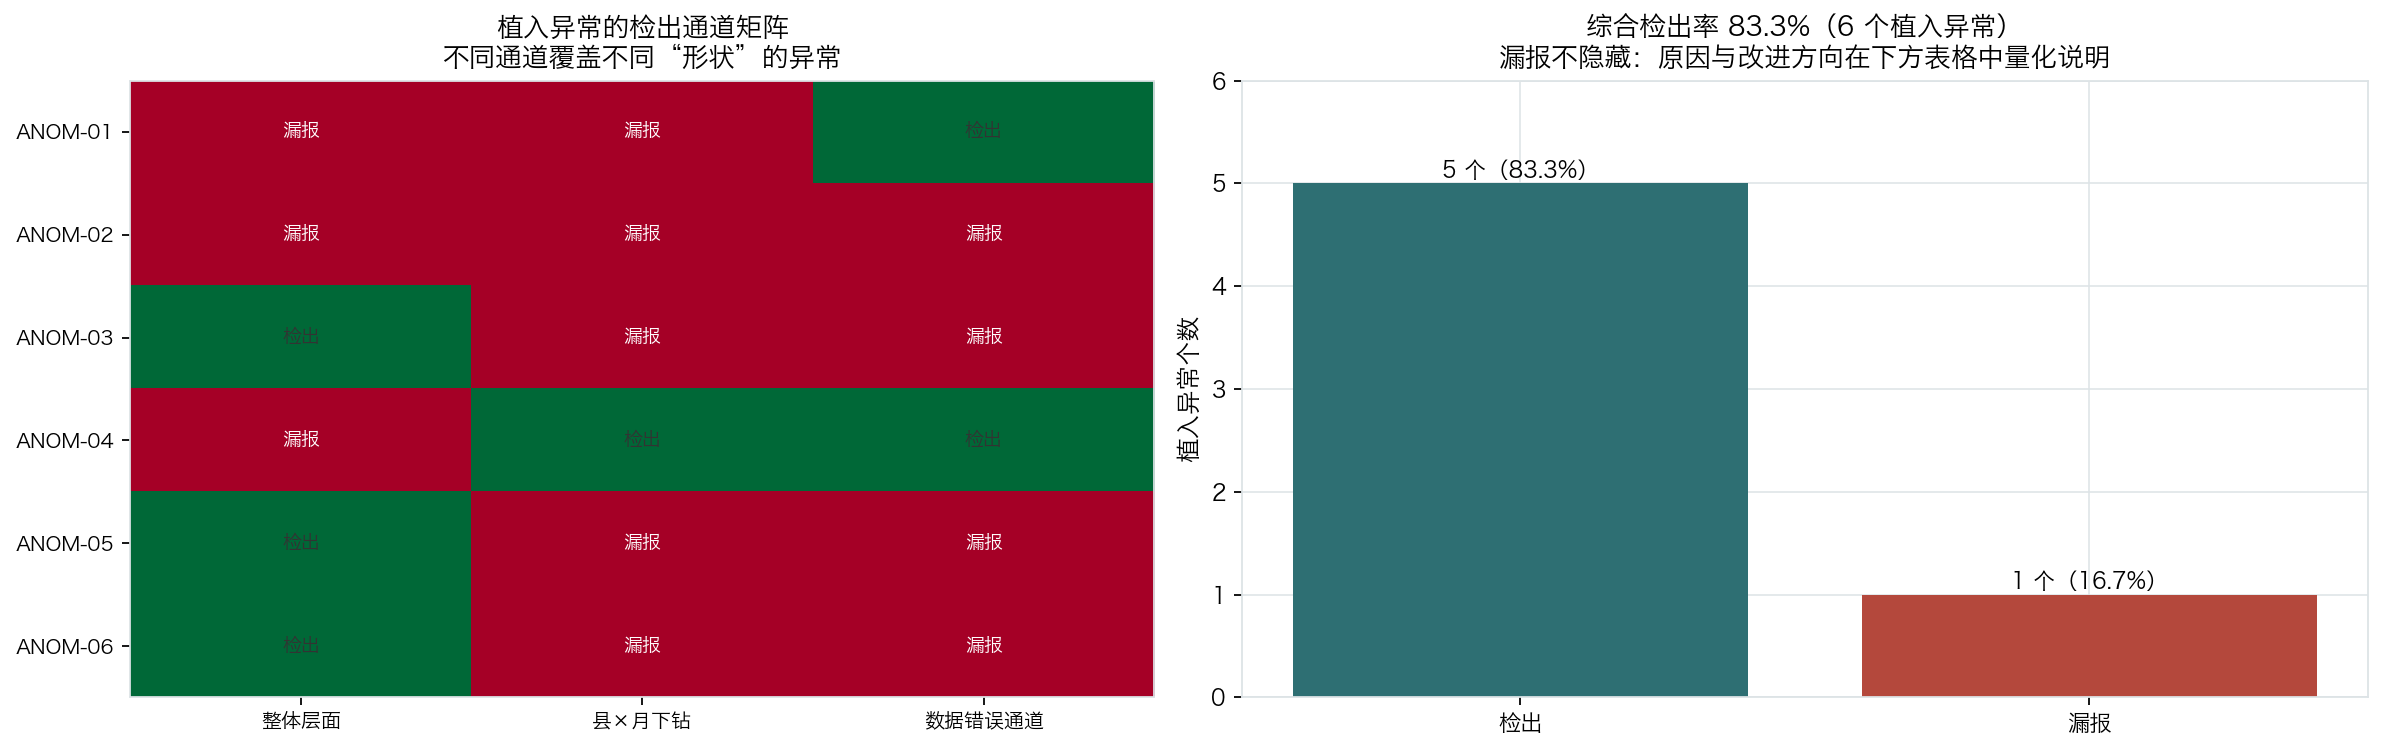

青绿=该通道检出，红=漏报。多通道并行的意义正在于此：没有单一通道能覆盖所有异常形状。
（本 notebook 自绘图表已保存：reports/figures/nb03_detection_score.png）


In [7]:
evaluation = evaluate_detection(cfg, monthly_anom, county_anom, data_errors)
display(evaluation[["异常编号", "植入月份", "植入范围", "植入指标", "偏离方向", "偏离幅度",
                    "真实成因类型", "整体层面检出", "县域下钻检出", "数据错误通道检出", "综合检出"]])

channels = ["整体层面检出", "县域下钻检出", "数据错误通道检出"]
hit_matrix = evaluation.set_index("异常编号")[channels].replace({"是": 1, "否": 0}).astype(int)
overall_rate = float((evaluation["综合检出"] == "是").mean())

by_cause = (evaluation.assign(命中=(evaluation["综合检出"] == "是").astype(int))
            .groupby("真实成因类型")["命中"].agg(["size", "sum"])
            .rename(columns={"size": "植入数", "sum": "检出数"}))
by_cause["检出率"] = (by_cause["检出数"] / by_cause["植入数"]).round(3)
display(by_cause)

misses = explain_misses(cfg, star, evaluation)
print(f"综合检出率：{int((evaluation['综合检出'] == '是').sum())}/{len(evaluation)} = {overall_rate:.1%}")
if len(misses):
    display(misses[["异常编号", "植入月份", "植入范围", "植入指标", "真实成因类型",
                    "实际偏离幅度", "序列稳健变异系数", "漏报原因", "改进方向"]])
else:
    print("全部植入异常至少被一个通道检出")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
im = ax.imshow(hit_matrix.to_numpy(), aspect="auto", cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(len(channels)), ["整体层面", "县×月下钻", "数据错误通道"], fontsize=9)
ax.set_yticks(range(len(hit_matrix)), hit_matrix.index, fontsize=9)
for i in range(hit_matrix.shape[0]):
    for j in range(hit_matrix.shape[1]):
        ax.text(j, i, "检出" if hit_matrix.iloc[i, j] else "漏报", ha="center", va="center",
                fontsize=8.5, color="white" if hit_matrix.iloc[i, j] == 0 else "#333333")
ax.set_title("植入异常的检出通道矩阵\n不同通道覆盖不同“形状”的异常", fontsize=12)
ax.grid(False)

ax = axes[1]
summary_bars = pd.DataFrame(
    {"检出": [int((evaluation["综合检出"] == "是").sum()), len(evaluation) - int((evaluation["综合检出"] == "是").sum())]},
    index=["检出", "漏报"])
colors = [cfg.color("primary"), cfg.color("danger")]
ax.bar(summary_bars.index, summary_bars["检出"], color=colors)
for i, v in enumerate(summary_bars["检出"]):
    ax.text(i, v + 0.05, f"{v} 个（{v / len(evaluation):.1%}）", ha="center", fontsize=10)
ax.set_ylabel("植入异常个数")
ax.set_ylim(0, len(evaluation))
ax.set_title(f"综合检出率 {overall_rate:.1%}（{len(evaluation)} 个植入异常）\n"
             "漏报不隐藏：原因与改进方向在下方表格中量化说明", fontsize=12)
fig.tight_layout()
show(fig, "nb03_detection_score",
     "青绿=该通道检出，红=漏报。多通道并行的意义正在于此：没有单一通道能覆盖所有异常形状。")

**这份"成绩单"的正确读法**：

- **不要只看总检出率**。更重要的是**哪个通道抓住了哪类异常**：整体层面擅长量级突变，
  县 × 月下钻擅长抓被总量平均掉的局部事故，数据错误通道擅长抓记录质量问题。
  三者是互补关系，缺一个就会出现系统性盲区。
- **漏报本身是结论**。被漏掉的异常，代码量化了两个原因：
  偏离幅度没有超出该序列自身的正常波动范围（信噪比不足），或者它恰好落在年度季节低谷（季节混淆）。
  这两种情况都**不能靠调低阈值解决**——调低阈值只会同时放进大量假阳性，毁掉预警的可信度。
- **正确的改进方向**是补充信息而不是降低门槛：引入业务事件日历（天气、交通、节庆）作为外生变量，
  或改用 CUSUM、变点检测这类对"持续小幅偏移"更敏感的方法。

> 对管理者的表达建议：不要说"我们的异常检测准确率 100%"，
> 而要说"我们覆盖了哪几类异常、每类由哪个通道负责、剩下的盲区需要什么数据才能补上"。
> 后者才是可信的数据能力描述。

## 7. 结论（量化）

下面实时计算本 notebook 的结论数字，可直接用于汇报。

In [8]:
svc_row = tsummary[tsummary["指标"] == service_key].iloc[0]
don_row = tsummary[tsummary["指标"] == donation_key].iloc[0]
elas = donation_service_elasticity(panel)
peak = season.loc[season["相对强度指数"].idxmax()]
trough = season.loc[season["相对强度指数"].idxmin()]
miss_count = len(misses)
detected = int((evaluation["综合检出"] == "是").sum())
de_months = sorted(data_errors["年月"].astype(str).unique().tolist()) if len(data_errors) else []

print("=" * 78)
print("结论摘要（全部由代码实时计算）")
print("=" * 78)
def trend_line(row):
    # 起始月为 0 的序列无法计算区间变化率（组织在窗口首月尚未开展该类服务），必须显式说明而不是打印 nan
    if pd.isna(row["区间变化率"]):
        return (f"{row['指标']} 起始月为 0，区间变化率不可计算；最新月 {row['最新值']:,.0f}，"
                f"季节强度 {row['季节强度']}，波动率 {row['波动率(变异系数)']:.2f}")
    return (f"{row['指标']} 区间变化 {row['区间变化率']:+.1%}（年化 {row['年化增长率CAGR']:+.1%}，"
            f"季节强度 {row['季节强度']}，波动率 {row['波动率(变异系数)']:.2f}）")


print(f"1) 趋势：{trend_line(svc_row)}；{trend_line(don_row)}；"
      f"剔除单笔最大捐赠后的可比口径见 §1。")
print(f"2) 季节：旺季 {peak['月度名称']}（指数 {peak['相对强度指数']:.2f}）、淡季 {trough['月度名称']}"
      f"（指数 {trough['相对强度指数']:.2f}），极差 {peak['相对强度指数'] / trough['相对强度指数']:.1f} 倍 —— "
      f"排班与预算应按此节奏分配，而非 12 等分。")
print(f"3) 异常：整体层面检出 {len(monthly_anom)} 个、县×月下钻检出 {len(county_anom)} 个、"
      f"数据错误通道检出 {len(data_errors)} 个（涉及月份：{'、'.join(de_months) if de_months else '无'}）。")
attr_lines = [f"{p}/{m} 主责单元={a['主责县域']}（{a['主责项目类别']}），成因判断={a['初步成因判断']}"
              for (p, m), a in attributions.items()]
print(f"4) 归因：{'；'.join(attr_lines) if attr_lines else '无可用归因目标'}。")
print(f"5) 可验证性：植入异常 {len(evaluation)} 个，综合检出 {detected} 个（{overall_rate:.1%}）；"
      f"漏报 {miss_count} 个，原因已在 §6 表格中量化。")
print(f"6) 弹性检验：捐赠→服务时长弹性点估计 {elas.get('elasticity', float('nan')):.3f}"
      f"（判定：{elas.get('verdict', '未提供')}，p={elas.get('p_value', float('nan')):.3f}）——"
      f"统计不显著时不能按点估计讲故事。")
print("=" * 78)

结论摘要（全部由代码实时计算）
1) 趋势：志愿服务时长 起始月为 0，区间变化率不可计算；最新月 3,193，季节强度 0.114，波动率 0.55；现金捐赠额 区间变化 +52.6%（年化 +19.1%，季节强度 0.047，波动率 0.49）；剔除单笔最大捐赠后的可比口径见 §1。
2) 季节：旺季 10月（指数 1.28）、淡季 2月（指数 0.74），极差 1.7 倍 —— 排班与预算应按此节奏分配，而非 12 等分。
3) 异常：整体层面检出 4 个、县×月下钻检出 3 个、数据错误通道检出 5 个（涉及月份：2024-02、2026-04、2026-06）。
4) 归因：2026-05/现金捐赠额 主责单元=香格里拉市（乡村振兴），成因判断=业务事件或真实波动（记录质量平稳）；2025-12/志愿服务时长 主责单元=香格里拉市（助老敬老），成因判断=业务事件或真实波动（记录质量平稳）。
5) 可验证性：植入异常 6 个，综合检出 5 个（83.3%）；漏报 1 个，原因已在 §6 表格中量化。
6) 弹性检验：捐赠→服务时长弹性点估计 0.524（判定：不显著，p=0.230）——统计不显著时不能按点估计讲故事。


### 移交清单（给 notebook 04 与业务方）

1. **口径约定**：所有趋势结论必须标注"是否剥离季节"与"是否含一次性大额捐赠"；这两条注释在 notebook 04 的评分卡与集中度分析中继续沿用。
2. **必须复盘的月份**：票数达到共识阈值且跨两个以上指标同时异常的月份（见 §3 投票矩阵），逐月产出复盘结论。
3. **需要校正的指标值**：数据错误通道检出的月份，其指标值在考核前必须校正（剔除或回填），并保留校正记录以备审计。
4. **需要补充的信息**：漏报异常的改进方向一致指向"外生事件日历"（天气/交通/节庆/政策）与变点检测方法——这是下一步数据建设的具体需求，而不是算法调参。
5. **可直接运营化的看板**：月度剔除率/修正率 SLO 看板 + 季节强度指数排班表。两者的投入产出比远高于继续优化异常检测算法的召回率。